# Product and Department Performance

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

In [2]:
sns.set_theme()

from scripts import visualization_config

## Which product categories sell the most units

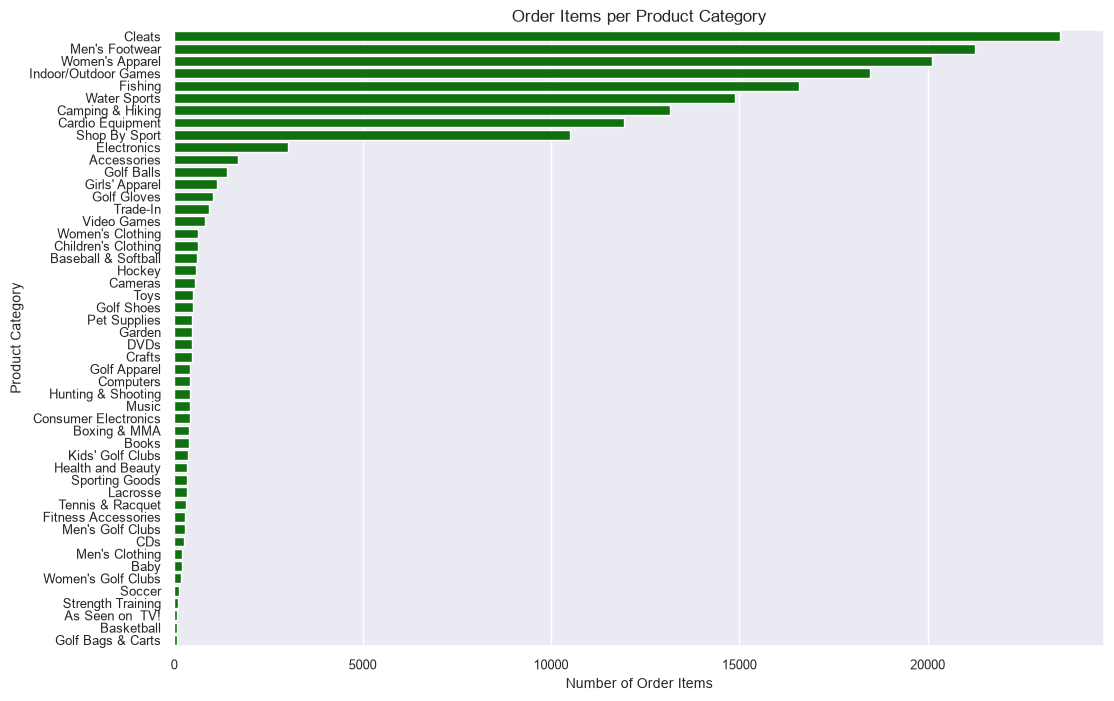

In [33]:
items_per_product_category = df.groupby('category_name').size().sort_values(ascending=False)

plt.figure(figsize=(12, 8))

sns.barplot(x=items_per_product_category.values, y=items_per_product_category.index, color='green')

plt.title('Order Items per Product Category')
plt.xlabel('Number of Order Items')
plt.ylabel('Product Category')

plt.savefig('../visualizations/order-items-per-product-category.png', bbox_inches='tight')
plt.show()

In [4]:
items_volume_per_category = (items_per_product_category / items_per_product_category.sum()).sort_values(ascending=False)

for category, volume in items_volume_per_category.head().items():
    print(f'{category}: {volume:.2%}')

Cleats: 13.61%
Men's Footwear: 12.31%
Women's Apparel: 11.64%
Indoor/Outdoor Games: 10.69%
Fishing: 9.61%


## Do certain product categories experience higher delivery delay rates?

In [29]:
overall_late_rate = df['late_delivery_risk'].mean()

category_delays = df.groupby('category_name')['late_delivery_risk'].agg(['mean', 'count'])
category_delays = category_delays[category_delays['count'] > 100]
category_delays['diff_from_overall'] = category_delays['mean'] - overall_late_rate

print(overall_late_rate)

category_delays.sort_values('diff_from_overall', ascending=False)

0.5728996035076549


,mean,count,diff_from_overall
category_name,,,
Lacrosse,0.626140,329,0.053240
Pet Supplies,0.614407,472,0.041507
Cameras,0.612100,562,0.039200
Accessories,0.597525,1697,0.024625
Music,0.594724,417,0.021825
Fitness Accessories,0.594595,296,0.021695
Boxing & MMA,0.592040,402,0.019140
Crafts,0.591703,458,0.018803
Sporting Goods,0.589286,336,0.016386


This table displays late delivery risk rates per product category, compared with the overall average late delivery risk.

It suggests that there aren't any product categories that experience higher delivery delay rates - the overall average late delivery risk being 57.29% with all items being at most +5 and -8 away from it.

Categories with fewer than 100 rows were excluded, as they produce noise.

To investigate further, I'll look at the average delivery delay in days for each category.

In [19]:
delayed_rows = df[df['late_delivery_risk'] == 1].copy()

delayed_rows['late_days'] = delayed_rows['days_for_shipping_real'] - delayed_rows['days_for_shipment_scheduled']

categories_average_delays = (
    delayed_rows
    .groupby('category_name')['late_days']
    .agg(['mean', 'count'])
)

filtered_categories = categories_average_delays[categories_average_delays['count'] > 100]

filtered_categories.sort_values('mean', ascending=False)

,mean,count
category_name,,
Trade-In,1.734317,542
Consumer Electronics,1.726891,238
Women's Clothing,1.700272,367
Children's Clothing,1.698276,348
Baseball & Softball,1.679083,349
Tennis & Racquet,1.666667,183
Video Games,1.665934,455
Computers,1.656250,224
Boxing & MMA,1.642857,238


The table unveils that baby products have the least amount of latency, 1.47 days on average, with trade-in items sitting at the top with 1.73 days on average.

These two categories are furthest apart and have a difference of 0.26 days difference on average.

This suggests that specific product categories don't experience higher delivery delay rates.

### Conclusion

Both tables suggest that no specific product categories experience higher delivery delay rates.

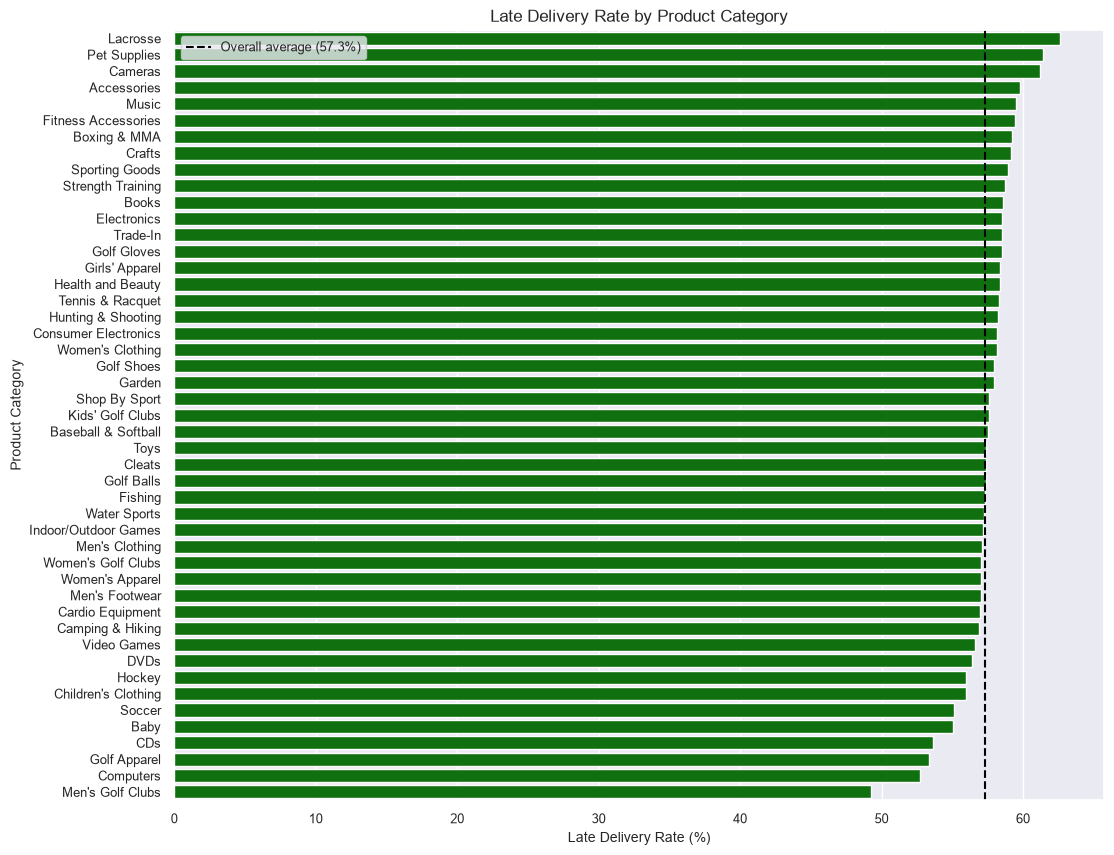

In [ ]:
chart_data = category_delays.sort_values('mean', ascending=False)

plt.figure(figsize=(12, 10))

sns.barplot(x=chart_data['mean'] * 100, y=chart_data.index, color='green')
plt.axvline(overall_late_rate * 100, color='black', linestyle='--',
            label=f'Overall average ({overall_late_rate:.1%})')

plt.title('Late Delivery Rate by Product Category')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Product Category')
plt.legend()

plt.savefig('../visualizations/late-delivery-rate-by-product-category.png', bbox_inches='tight')
plt.show()

## Which departments generate the most revenue and profit?

## Are there departments with high sales but relatively low profitability?